# Blind multifrequency fitting with closure quantities

This notebook fits the three blind UVFITS datasets without using true source parameters. Station-based gains are avoided by fitting closure phases and log closure amplitudes. Model quality is assessed with held-out closures and agreement between independent optimizer starts.


In [1]:
import ehtim as eh
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.optimize import differential_evolution, least_squares

RADPERUAS = np.pi / (180.0 * 3600.0 * 1e6)
np.set_printoptions(precision=4, suppress=True)



Welcome to eht-imaging!



## 1. Load blind UVFITS data

Log closure amplitudes are extracted before closure phases to avoid an `ehtim 1.2.10` record-array mutation issue seen in the 86 GHz file.


In [2]:
freqs = [15e9, 43e9, 86e9]
freq_labels = {15e9: "15 GHz", 43e9: "43 GHz", 86e9: "86 GHz"}
blind_files = {
    15e9: "blind_15GHz_noise.uvfits",
    43e9: "blind_43GHz_noise.uvfits",
    86e9: "blind_86GHz_noise.uvfits",
}
CLOSURE_SNR_CUT = 3.0

blind_obs = {freq: eh.obsdata.load_uvfits(blind_files[freq]) for freq in freqs}

def closure_dataset(obs):
    logcamp = obs.c_amplitudes(
        vtype="vis", mode="all", count="min", ctype="logcamp",
        debias=True, snrcut=CLOSURE_SNR_CUT,
    )
    cphase = obs.c_phases(
        vtype="vis", mode="all", count="min", ang_unit="rad",
        snrcut=CLOSURE_SNR_CUT,
    )
    return {"cphase": cphase, "logcamp": logcamp}

blind_closures_full = {freq: closure_dataset(blind_obs[freq]) for freq in freqs}

print(f"{'frequency':10s} {'visibilities':>12s} {'closure phase':>14s} {'log closure amp':>16s}")
print("-" * 58)
for freq in freqs:
    print(
        f"{freq_labels[freq]:10s} {len(blind_obs[freq].data):12d} "
        f"{len(blind_closures_full[freq]['cphase']):14d} "
        f"{len(blind_closures_full[freq]['logcamp']):16d}"
    )


Loading uvfits:  blind_15GHz_noise.uvfits
no IF in uvfits header!
POLREP_UVFITS: circ
Number of uvfits Correlation Products: 4
Loading uvfits:  blind_43GHz_noise.uvfits
no IF in uvfits header!
POLREP_UVFITS: circ
Number of uvfits Correlation Products: 4
Loading uvfits:  blind_86GHz_noise.uvfits
no IF in uvfits header!
POLREP_UVFITS: circ
Number of uvfits Correlation Products: 4
frequency  visibilities  closure phase  log closure amp
----------------------------------------------------------
15 GHz            17048          12848            12167
43 GHz            17048           6264             2651
86 GHz            17048           2434              284


## 2. Closure-identifiable source model

The 43 GHz core defines the reference frame. Jet positions are shared across frequencies, while the 15 and 86 GHz cores may shift by at most `MAX_CORE_SHIFT_UAS`. Component names shown in the final plot are assigned from the recovered spectral trend and geometry, not known true values.


In [3]:
def uas_to_rad(value):
    return value * RADPERUAS

N_CLOSURE_PARAMS = 19

def fractions_from_logits(core_logit, jet1_logit):
    values = np.array([core_logit, jet1_logit, 0.0])
    values -= np.max(values)
    weights = np.exp(values)
    return weights / np.sum(weights)

def core_shift_for_freq(q, freq):
    if freq == 15e9:
        return np.asarray(q[6:8])
    if freq == 43e9:
        return np.zeros(2)
    if freq == 86e9:
        return np.asarray(q[8:10])
    raise ValueError(freq)

def closure_q_to_components(q, freq):
    """Return shared jets in a frame centered on the frequency-dependent core."""
    i = freqs.index(freq)
    core_fraction, jet1_fraction, jet2_fraction = fractions_from_logits(q[2 * i], q[2 * i + 1])
    shift = core_shift_for_freq(q, freq)
    jet1 = np.asarray(q[10:12]) - shift
    jet2 = np.asarray(q[12:14]) - shift
    return {
        "core": (core_fraction, 0.0, 0.0, q[14 + i]),
        "jet1": (jet1_fraction, jet1[0], jet1[1], q[17]),
        "jet2": (jet2_fraction, jet2[0], jet2[1], q[18]),
    }

def gaussian_visibility(flux, x_uas, y_uas, fwhm_uas, u, v):
    x = uas_to_rad(x_uas)
    y = uas_to_rad(y_uas)
    sigma = uas_to_rad(fwhm_uas) / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    envelope = np.exp(-2.0 * np.pi**2 * sigma**2 * (u**2 + v**2))
    return flux * envelope * np.exp(2j * np.pi * (u * x + v * y))

def model_visibility(q, freq, u, v):
    return sum(
        gaussian_visibility(*component, u, v)
        for component in closure_q_to_components(q, freq).values()
    )


## 3. Closure likelihood and held-out validation

Every fifth observing time is reserved for validation. The optimizer sees only the training closures; validation `chi2` is computed afterward.


In [4]:
def wrap_phase(angle):
    return np.angle(np.exp(1j * angle))

def predict_cphase(q, freq, data):
    v1 = model_visibility(q, freq, data["u1"], data["v1"])
    v2 = model_visibility(q, freq, data["u2"], data["v2"])
    v3 = model_visibility(q, freq, data["u3"], data["v3"])
    return np.angle(v1 * v2 * v3)

def predict_logcamp(q, freq, data):
    floor = 1e-12
    amps = [
        np.maximum(np.abs(model_visibility(q, freq, data[f"u{i}"], data[f"v{i}"])), floor)
        for i in range(1, 5)
    ]
    return np.log(amps[0]) + np.log(amps[1]) - np.log(amps[2]) - np.log(amps[3])

def closure_residuals(q, datasets):
    blocks = []
    for freq in freqs:
        cp = datasets[freq]["cphase"]
        camp = datasets[freq]["logcamp"]
        if len(cp):
            sigma_cp = np.maximum(np.asarray(cp["sigmacp"], dtype=float), 1e-4)
            blocks.append(wrap_phase(cp["cphase"] - predict_cphase(q, freq, cp)) / sigma_cp)
        if len(camp):
            sigma_ca = np.maximum(np.asarray(camp["sigmaca"], dtype=float), 1e-4)
            blocks.append((camp["camp"] - predict_logcamp(q, freq, camp)) / sigma_ca)
    return np.concatenate(blocks)

def closure_chi2_red(q, datasets):
    residual = closure_residuals(q, datasets)
    return float(np.sum(residual**2) / max(len(residual) - len(q), 1))

def split_by_time(datasets, validation_stride=5):
    train, validation = {}, {}
    for freq in freqs:
        train[freq], validation[freq] = {}, {}
        for observable in ["cphase", "logcamp"]:
            data = datasets[freq][observable]
            unique_times = np.unique(data["time"])
            validation_times = unique_times[::validation_stride]
            validation_mask = np.isin(data["time"], validation_times)
            train[freq][observable] = data[~validation_mask]
            validation[freq][observable] = data[validation_mask]
    return train, validation


## 4. Search configuration

The fit is genuinely blind: no synthetic truth and no saved parameter vector are used. Differential evolution searches the bounded closure-parameter space, followed by broad random starts and local least-squares polishing. Set `RUN_PRESET = "serious"` for the full run.


In [5]:
RUN_PRESET = "serious"  # change to "serious" for the full run

if RUN_PRESET == "serious":
    alpha = 1
    N_RANDOM_STARTS = 500 * alpha
    N_POLISH = 40 * alpha
    MAX_NFEV = 1200
    MAX_POINTS_PER_TYPE_PER_FREQ = None
    DE_MAXITER = 200 * alpha
    DE_POPSIZE = 12 * alpha
else:
    N_RANDOM_STARTS = 20
    N_POLISH = 4
    MAX_NFEV = 100
    MAX_POINTS_PER_TYPE_PER_FREQ = 250
    DE_MAXITER = 3
    DE_POPSIZE = 4

def thin_datasets(datasets, max_points):
    if max_points is None:
        return datasets
    thinned = {}
    for freq in freqs:
        thinned[freq] = {}
        for observable in ["cphase", "logcamp"]:
            data = datasets[freq][observable]
            if len(data) <= max_points:
                thinned[freq][observable] = data
            else:
                indices = np.linspace(0, len(data) - 1, max_points, dtype=int)
                thinned[freq][observable] = data[indices]
    return thinned

blind_closures = thin_datasets(blind_closures_full, MAX_POINTS_PER_TYPE_PER_FREQ)
train_closures, validation_closures = split_by_time(blind_closures)

MAX_FWHM_UAS = 8000.0
MAX_CORE_SHIFT_UAS = 1000.0
MAX_JET_OFFSET_UAS = 20000.0
lower = np.array(
    [-6.0] * 6
    + [-MAX_CORE_SHIFT_UAS] * 4
    + [-MAX_JET_OFFSET_UAS] * 4
    + [30.0] * 5
)
upper = np.array(
    [6.0] * 6
    + [MAX_CORE_SHIFT_UAS] * 4
    + [MAX_JET_OFFSET_UAS] * 4
    + [MAX_FWHM_UAS] * 5
)


## 5. Blind per-band initialization

Each frequency is first fitted independently with broad, identical bounds. These fits are diagnostic and provide a data-derived initialization for the shared multifrequency model; no known component values are used.


In [6]:
BAND_PARAM_COUNT = 9
band_lower = np.array([-6.0, -6.0] + [-MAX_JET_OFFSET_UAS] * 4 + [30.0] * 3)
band_upper = np.array([6.0, 6.0] + [MAX_JET_OFFSET_UAS] * 4 + [MAX_FWHM_UAS] * 3)

def band_q_to_components(q):
    core_fraction, jet1_fraction, jet2_fraction = fractions_from_logits(q[0], q[1])
    return {
        "core": (core_fraction, 0.0, 0.0, q[6]),
        "jet1": (jet1_fraction, q[2], q[3], q[7]),
        "jet2": (jet2_fraction, q[4], q[5], q[8]),
    }

def band_model_visibility(q, u, v):
    return sum(gaussian_visibility(*component, u, v) for component in band_q_to_components(q).values())

def band_residuals(q, data):
    blocks = []
    cp = data["cphase"]
    camp = data["logcamp"]
    if len(cp):
        v1 = band_model_visibility(q, cp["u1"], cp["v1"])
        v2 = band_model_visibility(q, cp["u2"], cp["v2"])
        v3 = band_model_visibility(q, cp["u3"], cp["v3"])
        prediction = np.angle(v1 * v2 * v3)
        sigma = np.maximum(np.asarray(cp["sigmacp"], dtype=float), 1e-4)
        blocks.append(wrap_phase(cp["cphase"] - prediction) / sigma)
    if len(camp):
        floor = 1e-12
        amps = [
            np.maximum(np.abs(band_model_visibility(q, camp[f"u{i}"], camp[f"v{i}"])), floor)
            for i in range(1, 5)
        ]
        prediction = np.log(amps[0]) + np.log(amps[1]) - np.log(amps[2]) - np.log(amps[3])
        sigma = np.maximum(np.asarray(camp["sigmaca"], dtype=float), 1e-4)
        blocks.append((camp["camp"] - prediction) / sigma)
    return np.concatenate(blocks)

def band_chi2(q, data):
    residual = band_residuals(q, data)
    return float(np.sum(residual**2) / max(len(residual) - len(q), 1))

def fit_one_band(freq, seed):
    rng = np.random.default_rng(seed)
    coarse = {
        observable: values[np.linspace(0, len(values) - 1, min(len(values), 160), dtype=int)]
        for observable, values in train_closures[freq].items()
    }
    de = differential_evolution(
        lambda q: float(np.mean(band_residuals(q, coarse)**2)),
        bounds=list(zip(band_lower, band_upper)),
        seed=seed,
        maxiter=max(2, DE_MAXITER // 2),
        popsize=max(4, DE_POPSIZE // 2),
        polish=False,
        updating="immediate",
        workers=1,
    )
    starts = [de.x]
    for _ in range(5):
        start = de.x.copy()
        start[:2] += rng.normal(0.0, 0.3, size=2)
        start[2:6] += rng.normal(0.0, 250.0, size=4)
        start[6:9] *= rng.lognormal(0.0, 0.15, size=3)
        starts.append(np.clip(start, band_lower, band_upper))

    candidates = []
    for start in starts:
        result = least_squares(
            band_residuals, start, args=(train_closures[freq],),
            bounds=(band_lower, band_upper), method="trf", x_scale="jac",
            loss="soft_l1", f_scale=2.0,
            ftol=1e-8, xtol=1e-8, gtol=1e-8,
            max_nfev=min(MAX_NFEV, 500),
        )
        candidates.append((band_chi2(result.x, train_closures[freq]), result.x, result.status))
    return min(candidates, key=lambda item: item[0])

independent_fits = {freq: fit_one_band(freq, 8200 + i) for i, freq in enumerate(freqs)}

def aligned_band_components(fits):
    """Match independent components using geometry plus a rising-spectrum core score."""
    import itertools

    raw = {}
    for freq in freqs:
        components = list(band_q_to_components(fits[freq][1]).values())
        raw[freq] = components

    best_score, best = np.inf, None
    permutations = list(itertools.permutations(range(3)))
    for p15 in permutations:
        for p43 in permutations:
            for p86 in permutations:
                selected = {}
                for freq, permutation in zip(freqs, [p15, p43, p86]):
                    values = [raw[freq][index] for index in permutation]
                    core_xy = np.asarray(values[0][1:3])
                    selected[freq] = [
                        (value[0], *(np.asarray(value[1:3]) - core_xy), value[3])
                        for value in values
                    ]

                geometry = 0.0
                for component_index in [1, 2]:
                    positions = np.asarray([selected[freq][component_index][1:3] for freq in freqs])
                    widths = np.asarray([selected[freq][component_index][3] for freq in freqs])
                    geometry += np.sum(np.var(positions, axis=0)) / 1e6
                    geometry += np.var(widths) / 1e6

                core_flux = np.asarray([selected[freq][0][0] for freq in freqs])
                trend_penalty = 100.0 * (
                    max(0.0, core_flux[0] - core_flux[1])**2
                    + max(0.0, core_flux[1] - core_flux[2])**2
                )
                score = geometry + trend_penalty
                if score < best_score:
                    best_score, best = score, selected
    return best

def aligned_components_to_joint_seed(aligned):
    q = np.zeros(N_CLOSURE_PARAMS)
    for i, freq in enumerate(freqs):
        core, jet1, jet2 = aligned[freq]
        epsilon = 1e-8
        q[2 * i] = np.log((core[0] + epsilon) / (jet2[0] + epsilon))
        q[2 * i + 1] = np.log((jet1[0] + epsilon) / (jet2[0] + epsilon))
        q[14 + i] = core[3]

    jet1_positions = np.asarray([aligned[freq][1][1:3] for freq in freqs])
    jet2_positions = np.asarray([aligned[freq][2][1:3] for freq in freqs])
    q[10:12] = jet1_positions[1]
    q[12:14] = jet2_positions[1]

    shift15 = 0.5 * ((q[10:12] - jet1_positions[0]) + (q[12:14] - jet2_positions[0]))
    shift86 = 0.5 * ((q[10:12] - jet1_positions[2]) + (q[12:14] - jet2_positions[2]))
    q[6:8] = np.clip(shift15, -MAX_CORE_SHIFT_UAS, MAX_CORE_SHIFT_UAS)
    q[8:10] = np.clip(shift86, -MAX_CORE_SHIFT_UAS, MAX_CORE_SHIFT_UAS)
    q[17] = np.median([aligned[freq][1][3] for freq in freqs])
    q[18] = np.median([aligned[freq][2][3] for freq in freqs])
    return np.clip(q, lower, upper)

aligned_independent_components = aligned_band_components(independent_fits)
q_data_initial = aligned_components_to_joint_seed(aligned_independent_components)

print(f"{'frequency':10s} {'independent train chi2':>24s}")
print("-" * 36)
for freq in freqs:
    print(f"{freq_labels[freq]:10s} {independent_fits[freq][0]:24.3f}")

def robust_keep_mask(residual, minimum_sigma=8.0):
    absolute = np.abs(np.asarray(residual, dtype=float))
    center = np.median(absolute)
    mad = 1.4826 * np.median(np.abs(absolute - center))
    limit = max(minimum_sigma, center + 6.0 * max(mad, 1e-6))
    return absolute <= limit, limit

def filter_training_closures(q, datasets):
    filtered = {}
    for freq in freqs:
        filtered[freq] = {}
        cp = datasets[freq]["cphase"]
        cp_sigma = np.maximum(np.asarray(cp["sigmacp"], dtype=float), 1e-4)
        cp_residual = wrap_phase(cp["cphase"] - predict_cphase(q, freq, cp)) / cp_sigma
        cp_keep, cp_limit = robust_keep_mask(cp_residual)
        filtered[freq]["cphase"] = cp[cp_keep]

        camp = datasets[freq]["logcamp"]
        camp_sigma = np.maximum(np.asarray(camp["sigmaca"], dtype=float), 1e-4)
        camp_residual = (camp["camp"] - predict_logcamp(q, freq, camp)) / camp_sigma
        camp_keep, camp_limit = robust_keep_mask(camp_residual)
        filtered[freq]["logcamp"] = camp[camp_keep]

        print(
            f"{freq_labels[freq]} retained CP {cp_keep.sum()}/{len(cp)} (limit {cp_limit:.1f}), "
            f"logCA {camp_keep.sum()}/{len(camp)} (limit {camp_limit:.1f})"
        )
    return filtered

joint_train_closures = filter_training_closures(q_data_initial, train_closures)


frequency    independent train chi2
------------------------------------
15 GHz                      793.813
43 GHz                     1006.992
86 GHz                      542.006
15 GHz retained CP 10272/10272 (limit 1428.4), logCA 9226/9727 (limit 574.0)
43 GHz retained CP 4629/5010 (limit 8.8), logCA 2119/2119 (limit 252.0)
86 GHz retained CP 1931/1945 (limit 268.8), logCA 225/225 (limit 370.1)


## 6. Joint blind multifrequency fit

The shared-geometry fit starts from the independent-band solution, differential evolution, and broad random candidates. Local polishing uses a robust loss on filtered training closures; validation closures remain untouched.


In [7]:
def random_start(rng):
    q = rng.uniform(lower, upper)
    q[:6] = rng.uniform(-3.0, 3.0, size=6)
    q[14:19] = rng.uniform(80.0, 1500.0, size=5)
    return q

def fit_blind_closures(seed=8101):
    rng = np.random.default_rng(seed)
    global_closures = thin_datasets(joint_train_closures, 120)

    def global_objective(q):
        residual = closure_residuals(q, global_closures)
        return float(np.mean(residual**2))

    de_result = differential_evolution(
        global_objective,
        bounds=list(zip(lower, upper)),
        seed=seed,
        maxiter=DE_MAXITER,
        popsize=DE_POPSIZE,
        polish=False,
        updating="immediate",
        workers=1,
    )

    starts = [q_data_initial.copy(), de_result.x.copy()]
    starts.extend(random_start(rng) for _ in range(N_RANDOM_STARTS))
    for _ in range(min(10, N_RANDOM_STARTS // 4)):
        q_de = de_result.x.copy()
        q_de[:6] += rng.normal(0.0, 0.25, size=6)
        q_de[6:10] += rng.normal(0.0, 50.0, size=4)
        q_de[10:14] += rng.normal(0.0, 120.0, size=4)
        q_de[14:19] *= rng.lognormal(0.0, 0.10, size=5)
        starts.append(np.clip(q_de, lower, upper))

    raw_scores = np.array([closure_chi2_red(q, joint_train_closures) for q in starts])
    polished = []
    for idx in np.argsort(raw_scores)[:N_POLISH]:
        result = least_squares(
            closure_residuals, starts[idx], args=(joint_train_closures,), bounds=(lower, upper),
            method="trf", x_scale="jac", loss="soft_l1", f_scale=2.0,
            ftol=1e-9, xtol=1e-9, gtol=1e-9, max_nfev=MAX_NFEV,
        )
        polished.append({
            "q": result.x,
            "train_chi2": closure_chi2_red(result.x, joint_train_closures),
            "raw_train_chi2": closure_chi2_red(result.x, train_closures),
            "validation_chi2": closure_chi2_red(result.x, validation_closures),
            "full_chi2": closure_chi2_red(result.x, blind_closures),
            "status": result.status,
        })
    return sorted(polished, key=lambda row: row["train_chi2"]), raw_scores, de_result

solutions, raw_scores, de_result = fit_blind_closures()
best_solution = solutions[0]
q_fit = best_solution["q"]

print(
    f"Preset: {RUN_PRESET}; starts={N_RANDOM_STARTS}, polished={N_POLISH}, "
    f"max_nfev={MAX_NFEV}, DE generations={DE_MAXITER}, DE popsize={DE_POPSIZE}"
)
print(f"{'rank':>4s} {'filtered train':>14s} {'raw train':>12s} {'validation':>12s} {'full':>11s} {'status':>7s}")
print("-" * 70)
for rank, solution in enumerate(solutions, start=1):
    print(
        f"{rank:4d} {solution['train_chi2']:14.3f} {solution['raw_train_chi2']:12.3f} "
        f"{solution['validation_chi2']:12.3f} {solution['full_chi2']:11.3f} "
        f"{solution['status']:7d}"
    )


Preset: serious; starts=500, polished=40, max_nfev=1200, DE generations=200, DE popsize=12
rank filtered train    raw train   validation        full  status
----------------------------------------------------------------------
   1        854.762      832.321      844.161     834.259       2
   2        854.762      832.321      844.161     834.259       2
   3        854.762      832.321      844.161     834.259       2
   4        854.762      832.321      844.161     834.259       2
   5        854.762      832.321      844.161     834.259       2
   6        854.762      832.321      844.161     834.259       2
   7        854.762      832.321      844.161     834.259       2
   8        854.762      832.321      844.161     834.259       3
   9        854.762      832.321      844.161     834.259       2
  10        854.762      832.321      844.161     834.259       2
  11        854.762      832.321      844.161     834.259       2
  12        854.762      832.321      844.161 

In [8]:
def one_frequency_dataset(datasets, selected_freq):
    empty = {"cphase": np.array([], dtype=datasets[selected_freq]["cphase"].dtype),
             "logcamp": np.array([], dtype=datasets[selected_freq]["logcamp"].dtype)}
    return {
        freq: datasets[freq] if freq == selected_freq else empty
        for freq in freqs
    }

print()
print(f"{'frequency':10s} {'train chi2':>12s} {'validation chi2':>16s}")
print("-" * 41)
for freq in freqs:
    train_one = one_frequency_dataset(train_closures, freq)
    validation_one = one_frequency_dataset(validation_closures, freq)
    print(
        f"{freq_labels[freq]:10s} {closure_chi2_red(q_fit, train_one):12.3f} "
        f"{closure_chi2_red(q_fit, validation_one):16.3f}"
    )



frequency    train chi2  validation chi2
-----------------------------------------
15 GHz          794.369          805.997
43 GHz         1010.957         1034.513
86 GHz          609.085          629.474


In [9]:
def solution_distance(q_a, q_b):
    position_rms = float(np.sqrt(np.mean((q_a[6:14] - q_b[6:14])**2)))
    fwhm_rms = float(np.sqrt(np.mean((q_a[14:19] - q_b[14:19])**2)))
    fraction_differences = []
    for freq in freqs:
        a = np.array([component[0] for component in closure_q_to_components(q_a, freq).values()])
        b = np.array([component[0] for component in closure_q_to_components(q_b, freq).values()])
        fraction_differences.extend(a - b)
    fraction_rms = float(np.sqrt(np.mean(np.asarray(fraction_differences)**2)))
    return position_rms, fwhm_rms, fraction_rms

print(f"{'rank':>4s} {'position RMS vs best':>21s} {'FWHM RMS vs best':>18s} {'fraction RMS':>13s}")
print("-" * 62)
for rank, solution in enumerate(solutions, start=1):
    pos_rms, fwhm_rms, frac_rms = solution_distance(q_fit, solution["q"])
    print(f"{rank:4d} {pos_rms:21.3f} {fwhm_rms:18.3f} {frac_rms:13.5f}")


rank  position RMS vs best   FWHM RMS vs best  fraction RMS
--------------------------------------------------------------
   1                 0.000              0.000       0.00000
   2                 0.001              0.000       0.00000
   3              4102.054           2815.166       0.55429
   4                 0.000              0.000       0.00000
   5                 0.001              0.000       0.00000
   6                 0.000              0.000       0.00000
   7                 0.000              0.000       0.00000
   8                 0.001              0.000       0.00000
   9                 0.001              0.000       0.00000
  10                 0.002              0.001       0.00000
  11                 0.001              0.000       0.00000
  12                 0.001              0.000       0.00000
  13              8461.464           3271.646       0.53813
  14             12126.712           2019.574       0.62033
  15              9935.178           

## 7. Recovered blind source and solution stability

The core is fixed at `(0, 0)` in every panel. Solid components show the best blind solution; other polished candidates are faint. Coordinates are relative to the core, and circle diameter is the fitted FWHM.


Recovered label mapping: {'core': 'jet1', 'jet1': 'jet2', 'jet2': 'core'}


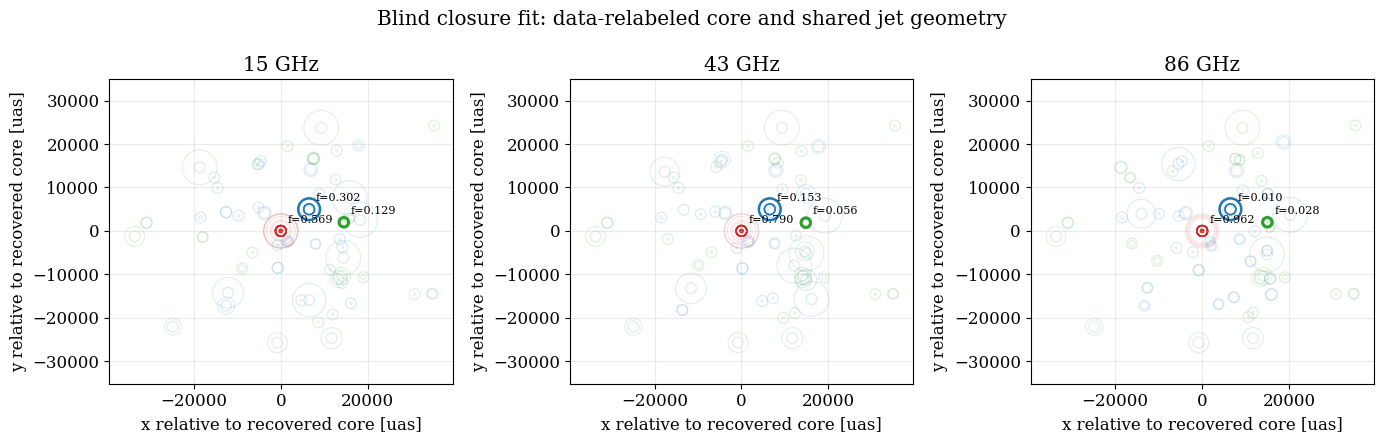

In [10]:
component_colors = {"core": "tab:red", "jet1": "tab:blue", "jet2": "tab:green"}

def recovered_label_mapping(q):
    names = ["core", "jet1", "jet2"]
    fractions = {
        name: np.asarray([closure_q_to_components(q, freq)[name][0] for freq in freqs])
        for name in names
    }
    physical_core = max(names, key=lambda name: fractions[name][-1] - fractions[name][0])
    remaining = [name for name in names if name != physical_core]

    core_43 = np.asarray(closure_q_to_components(q, 43e9)[physical_core][1:3])
    remaining.sort(
        key=lambda name: np.linalg.norm(
            np.asarray(closure_q_to_components(q, 43e9)[name][1:3]) - core_43
        )
    )
    return {"core": physical_core, "jet1": remaining[0], "jet2": remaining[1]}

def canonical_components(q, freq):
    raw = closure_q_to_components(q, freq)
    mapping = recovered_label_mapping(q)
    core_xy = np.asarray(raw[mapping["core"]][1:3])
    canonical = {}
    for output_name, raw_name in mapping.items():
        fraction, x, y, width = raw[raw_name]
        xy = np.asarray([x, y]) - core_xy
        canonical[output_name] = (fraction, xy[0], xy[1], width)
    return canonical

best_mapping = recovered_label_mapping(q_fit)
print("Recovered label mapping:", best_mapping)

def plot_components(q, ax, freq, title, alpha=1.0, linewidth=1.8, annotate=True):
    components = canonical_components(q, freq)
    for name, color in component_colors.items():
        fraction, x, y, width = components[name]
        ax.add_patch(Circle((x, y), width / 2.0, fill=False, linewidth=linewidth, color=color, alpha=alpha))
        ax.scatter(x, y, marker="o", s=60, facecolors="none", edgecolors=color, alpha=alpha, label=name)
        if annotate:
            ax.annotate(f"f={fraction:.3f}", (x, y), xytext=(5, 6), textcoords="offset points", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("x relative to recovered core [uas]")
    ax.set_ylabel("y relative to recovered core [uas]")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.25)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, freq in zip(axes, freqs):
    for candidate in solutions[1:]:
        plot_components(candidate["q"], ax, freq, "", alpha=0.14, linewidth=0.8, annotate=False)
    plot_components(q_fit, ax, freq, freq_labels[freq], alpha=1.0, linewidth=1.8, annotate=True)
fig.suptitle("Blind closure fit: data-relabeled core and shared jet geometry")
fig.tight_layout()
plt.show()


## 8. Held-out closure diagnostics

Points should follow the diagonal without strong curvature or frequency-dependent offsets. These plots are the blind-data replacement for a true-versus-recovered comparison.


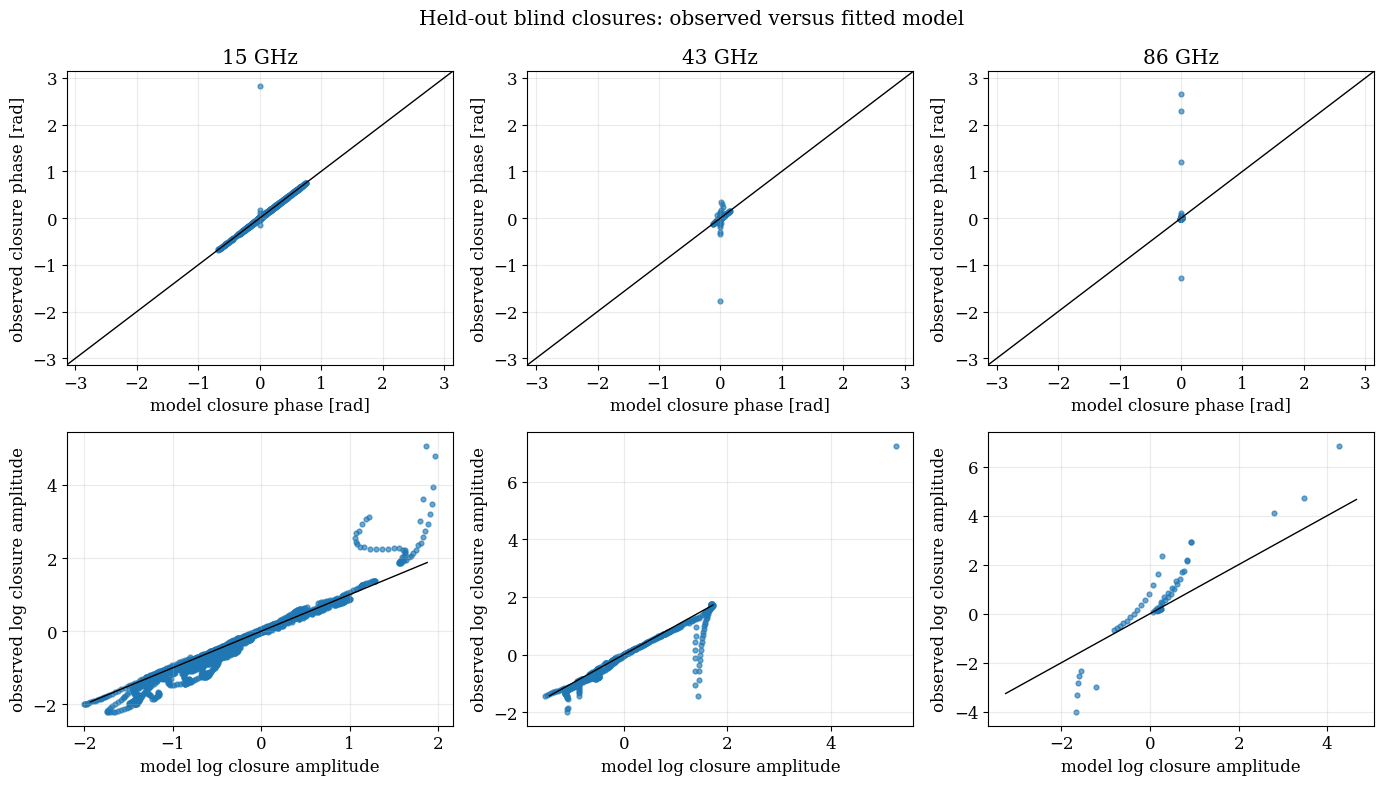

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, freq in enumerate(freqs):
    cp = validation_closures[freq]["cphase"]
    camp = validation_closures[freq]["logcamp"]

    cp_model = predict_cphase(q_fit, freq, cp)
    axes[0, col].scatter(cp_model, cp["cphase"], s=12, alpha=0.65)
    axes[0, col].plot([-np.pi, np.pi], [-np.pi, np.pi], color="black", linewidth=1)
    axes[0, col].set_xlim(-np.pi, np.pi)
    axes[0, col].set_ylim(-np.pi, np.pi)
    axes[0, col].set_title(freq_labels[freq])
    axes[0, col].set_xlabel("model closure phase [rad]")
    axes[0, col].set_ylabel("observed closure phase [rad]")
    axes[0, col].grid(alpha=0.25)

    camp_model = predict_logcamp(q_fit, freq, camp)
    combined = np.concatenate([camp_model, camp["camp"]])
    limits = [np.nanpercentile(combined, 1), np.nanpercentile(combined, 99)]
    axes[1, col].scatter(camp_model, camp["camp"], s=12, alpha=0.65)
    axes[1, col].plot(limits, limits, color="black", linewidth=1)
    axes[1, col].set_xlabel("model log closure amplitude")
    axes[1, col].set_ylabel("observed log closure amplitude")
    axes[1, col].grid(alpha=0.25)

fig.suptitle("Held-out blind closures: observed versus fitted model")
fig.tight_layout()
plt.show()


## Interpretation

A defensible blind result requires similar training and validation `chi2`, agreement among the best independent starts, and structure-free held-out residuals. The recovered absolute sky position and total flux remain unknowable from closures alone; they require calibrated amplitudes or external constraints.


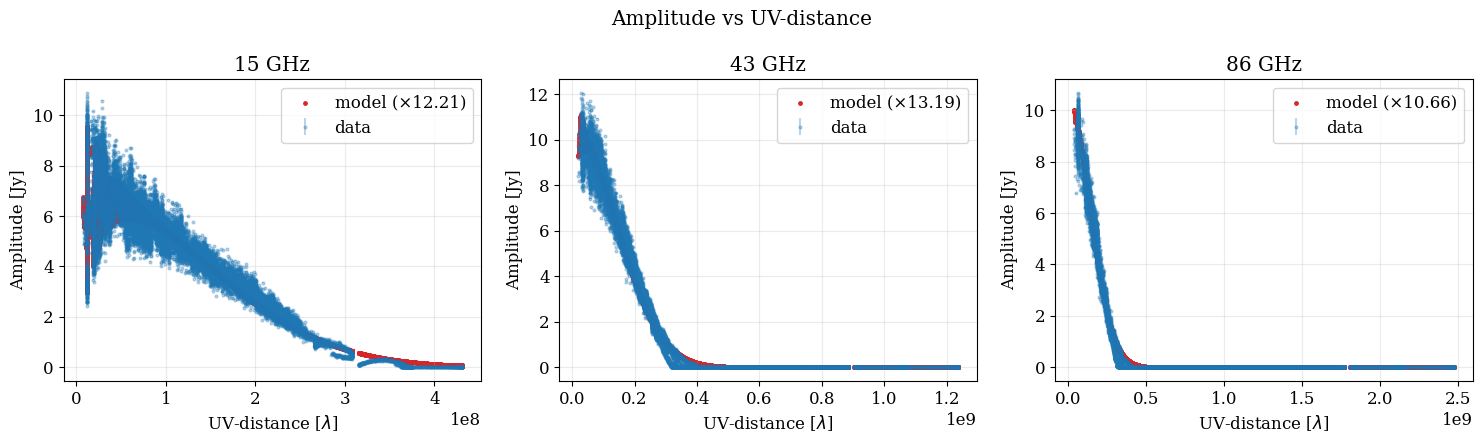

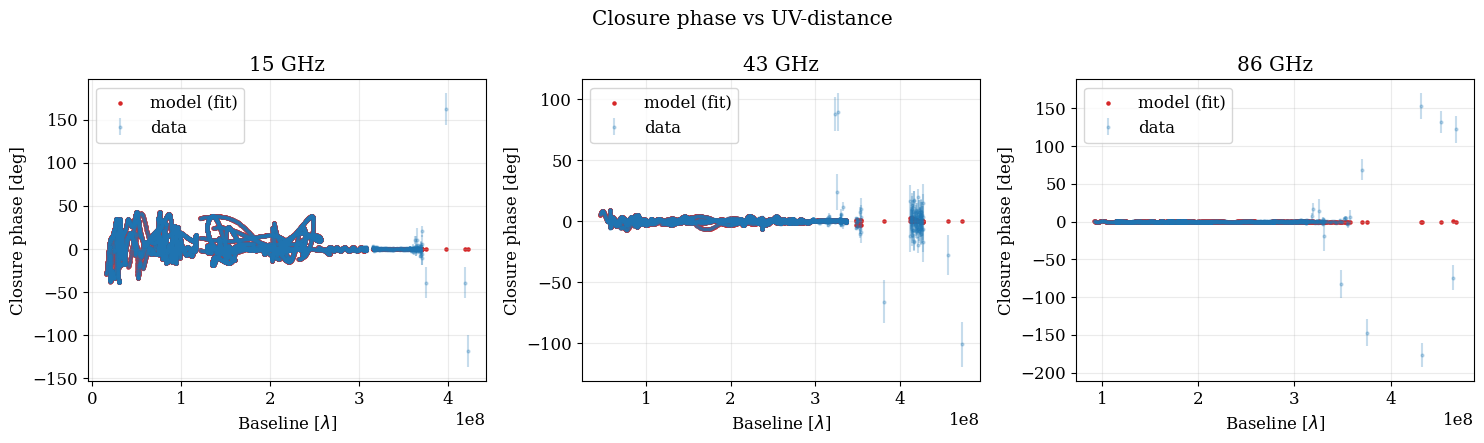

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, freq in zip(axes, freqs):
    dat = blind_obs[freq].unpack(["u", "v", "vis", "sigma"], mode="all", conj=False)
    u, v, vis, sigma = dat["u"], dat["v"], dat["vis"], dat["sigma"].real
    uvdist = np.sqrt(u**2 + v**2)

    amp_obs = np.abs(vis)
    amp_model_raw = np.abs(model_visibility(q_fit, freq, u, v))  # en fracciones, no Jy

    scale = np.sum(amp_obs * amp_model_raw) / np.sum(amp_model_raw**2)
    amp_model = scale * amp_model_raw

    order = np.argsort(uvdist)
    ax.errorbar(uvdist, amp_obs, yerr=sigma, fmt='.', color='tab:blue',
                alpha=0.3, markersize=4, label='data')
    ax.scatter(uvdist[order], amp_model[order], s=6, color='tab:red',
               label=f'model (×{scale:.2f})')
    ax.set_title(freq_labels[freq])
    ax.set_xlabel(r"UV-distance [$\lambda$]")
    ax.set_ylabel("Amplitude [Jy]")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Amplitude vs UV-distance")
fig.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, freq in zip(axes, freqs):
    cp = blind_closures_full[freq]["cphase"]
    b1 = np.sqrt(cp["u1"]**2 + cp["v1"]**2)
    b2 = np.sqrt(cp["u2"]**2 + cp["v2"]**2)
    b3 = np.sqrt(cp["u3"]**2 + cp["v3"]**2)
    uvdist_tri = np.maximum(np.maximum(b1, b2), b3)

    cphase_obs = np.degrees(cp["cphase"])
    cphase_model = np.degrees(predict_cphase(q_fit, freq, cp))
    sigma_cp = np.degrees(np.maximum(np.asarray(cp["sigmacp"], dtype=float), 1e-4))

    order = np.argsort(uvdist_tri)
    ax.errorbar(uvdist_tri, cphase_obs, yerr=sigma_cp, fmt='.', color='tab:blue',
                alpha=0.25, markersize=4, label='data')
    ax.scatter(uvdist_tri[order], cphase_model[order], s=5, color='tab:red',
               label='model (fit)')
    ax.set_title(freq_labels[freq])
    ax.set_xlabel(r"Baseline [$\lambda$]")
    ax.set_ylabel("Closure phase [deg]")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Closure phase vs UV-distance")
fig.tight_layout()
plt.show()

In [13]:
print("\nParameters:")
for freq in freqs:
    print(f"\\n--- {freq_labels[freq]} ---")
    componentes = canonical_components(q_fit, freq)
    for nombre, valores in componentes.items():
        print(f"{nombre}: Flux={valores[0]:.3f}, x_pos={valores[1]:.3f} µas, y_pos={valores[2]:.3f} µas, FWHM={valores[3]:.3f} µas")
        


Parameters:
\n--- 15 GHz ---
core: Flux=0.569, x_pos=0.000 µas, y_pos=0.000 µas, FWHM=549.261 µas
jet1: Flux=0.302, x_pos=6509.950 µas, y_pos=4992.789 µas, FWHM=5000.429 µas
jet2: Flux=0.129, x_pos=14501.639 µas, y_pos=1998.285 µas, FWHM=2037.526 µas
\n--- 43 GHz ---
core: Flux=0.790, x_pos=0.000 µas, y_pos=0.000 µas, FWHM=549.261 µas
jet1: Flux=0.153, x_pos=6509.950 µas, y_pos=4992.789 µas, FWHM=5000.429 µas
jet2: Flux=0.056, x_pos=14806.438 µas, y_pos=1899.165 µas, FWHM=2035.416 µas
\n--- 86 GHz ---
core: Flux=0.962, x_pos=0.000 µas, y_pos=0.000 µas, FWHM=549.261 µas
jet1: Flux=0.010, x_pos=6509.950 µas, y_pos=4992.789 µas, FWHM=5000.429 µas
jet2: Flux=0.028, x_pos=15002.260 µas, y_pos=2000.244 µas, FWHM=2022.835 µas


In [14]:
# relative to 43 ghz
shift_15_vs_43 = q_fit[6:8]  
shift_86_vs_43 = q_fit[8:10] 

shift_86_vs_15 = shift_15_vs_43 - shift_86_vs_43

print(f"Shift 15 GHz -> 43 GHz: dx = {shift_15_vs_43[0]:.3f} µas, dy = {shift_15_vs_43[1]:.3f} µas")
print(f"Shift 86 GHz -> 43 GHz: dx = {shift_86_vs_43[0]:.3f} µas, dy = {shift_86_vs_43[1]:.3f} µas")
print(f"Shift 86 GHz -> 15 GHz: dx = {shift_86_vs_15[0]:.3f} µas, dy = {shift_86_vs_15[1]:.3f} µas")

Shift 15 GHz -> 43 GHz: dx = -304.799 µas, dy = 99.120 µas
Shift 86 GHz -> 43 GHz: dx = 195.822 µas, dy = 101.079 µas
Shift 86 GHz -> 15 GHz: dx = -500.621 µas, dy = -1.959 µas
